# 05. Preprocessing

**Krok procesu:** 3. Przetwarzanie wstępne, potem bramka 4.

Preprocessing to deterministyczne przekształcenie wejścia, takie samo w treningu i na telefonie.
Nie dokłada nowych przykładów (to robi augmentacja w `06_augmentation.ipynb`).

Sprawdzamy cztery warianty, każdy dokłada coś do P1:

| Wariant | Co robi | Po co |
|---|---|---|
| P1 `wrist_scale` | nadgarstek w punkcie (0, 0), dłoń przeskalowana do koła jednostkowego | usuwa położenie i wielkość dłoni w kadrze |
| P2 `wrist_scale_upright` | P1 + obrót, żeby nadgarstek -> środkowy palec wskazywał w górę | usuwa przechylenie dłoni |
| P3 `wrist_scale_angles` | P1 + 15 kątów zgięcia w stawach palców | podaje wprost to, co mówi o wyprostowaniu palca |
| P4 `wrist_scale_upright_angles` | P2 + 15 kątów zgięcia | obie zmiany naraz |

P2 nie zabiera informacji potrzebnej do liczenia. Jedyna para gestów, która różni się głównie obrotem, to `like`
i `dislike` (kciuk w górę i w dół), a obie mają 1 palec. Gesty `*_inverted` w HaGRID nie są odwrócone do góry
nogami. W danych 100% z nich ma palce skierowane w górę, więc to raczej dłoń pokazana wierzchem.

Ważna obserwacja z danych: prawie wszystkie dłonie w HaGRID są pionowe (palce w górę). Wyjątki to gesty z kciukiem
w bok, jak `like` i `dislike`. Model nie widział więc przechylonych dłoni, a na telefonie będą częste.

Model zostaje bez zmian (MLP 128-64, domyślne parametry), żeby różnica wynikała tylko z preprocessingu.
Zasady bramki są opisane w `04_baseline.ipynb`.

In [1]:
import sys
sys.path.insert(0, "../src")

import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from pipeline import PREPROCESS, gate, load_split, macro_f1 as f1_macro, run_experiment, stress_set

FIG = Path("../reports/figures")
GATES = Path("../experiments/gates.json")
LOG = Path("../experiments/log.csv")
sns.set_theme(style="whitegrid")

lm_tr, y_tr, _ = load_split("train")
lm_va, y_va, _ = load_split("val")
lm_st = stress_set(lm_va)

def mlp_default(seed):
    return make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(128, 64), early_stopping=True,
                                                         max_iter=50, random_state=seed))

log = pd.read_csv(LOG).set_index("experiment_id")
current = log.loc["B0"].to_dict()
current_id = "B0"

In [2]:
variants = [("P1", "wrist_scale", "nadgarstek w (0, 0), skala do koła jednostkowego"),
            ("P2", "wrist_scale_upright", "P1 + obrót dłoni do pionu"),
            ("P3", "wrist_scale_angles", "P1 + 15 kątów zgięcia w stawach"),
            ("P4", "wrist_scale_upright_angles", "P2 + 15 kątów zgięcia w stawach")]
results, decisions = {"B0": current}, []
for exp_id, prep_name, desc in variants:
    prep = PREPROCESS[prep_name]
    res, _ = run_experiment(exp_id, "preprocessing", mlp_default, prep(lm_tr), y_tr, prep(lm_va), y_va, prep(lm_st),
                            notes={"model": "MLP 128-64, domyślne parametry", "notes": desc})
    passed, reasons = gate(current, res)
    decisions.append({"eksperyment": exp_id, "porównanie z": current_id, "bramka": "przechodzi" if passed else "odrzucony",
                      "powody": "; ".join(reasons)})
    results[exp_id] = res
    if passed:
        current, current_id = res, exp_id

pd.DataFrame(decisions)

[codecarbon INFO @ 17:07:23] offline tracker init


[codecarbon WARNING @ 17:07:23] Multiple instances of codecarbon are allowed to run at the same time.


,eksperyment,porównanie z,bramka,powody
0,P1,B0,przechodzi,"stress F1 +0.0458 (próg szumu 0.0260), val F1 ..."
1,P2,P1,odrzucony,"stress F1 +0.0429 (próg szumu 0.0260), val F1 ..."
2,P3,P1,odrzucony,"stress F1 +0.0061 (próg szumu 0.0260), val F1 ..."
3,P4,P1,odrzucony,"stress F1 +0.0422 (próg szumu 0.0260), val F1 ..."


In [3]:
table = pd.DataFrame(results).T[["val_macro_f1", "val_macro_f1_std", "val_stress_macro_f1", "val_stress_macro_f1_std",
                                 "train_time_s", "energy_kwh", "co2_g", "model_size_kb", "latency_ms"]].astype(float)
table.style.format({"val_macro_f1": "{:.4f}", "val_macro_f1_std": "{:.4f}", "val_stress_macro_f1": "{:.4f}",
                    "val_stress_macro_f1_std": "{:.4f}", "train_time_s": "{:.1f}", "energy_kwh": "{:.6f}",
                    "co2_g": "{:.3f}", "model_size_kb": "{:.0f}", "latency_ms": "{:.3f}"})

,val_macro_f1,val_macro_f1_std,val_stress_macro_f1,val_stress_macro_f1_std,train_time_s,energy_kwh,co2_g,model_size_kb,latency_ms
B0,0.9911,0.0004,0.9011,0.0066,48.6,0.000200,0.132,175,0.139
P1,0.9931,0.0002,0.9469,0.0130,37.6,0.000154,0.102,175,0.137
P2,0.9913,0.0003,0.9898,0.0003,38.1,0.000159,0.105,175,0.136
P3,0.9931,0.0002,0.9530,0.0015,35.2,0.000143,0.095,198,0.139
P4,0.9915,0.0002,0.9891,0.0007,37.3,0.000152,0.100,198,0.136


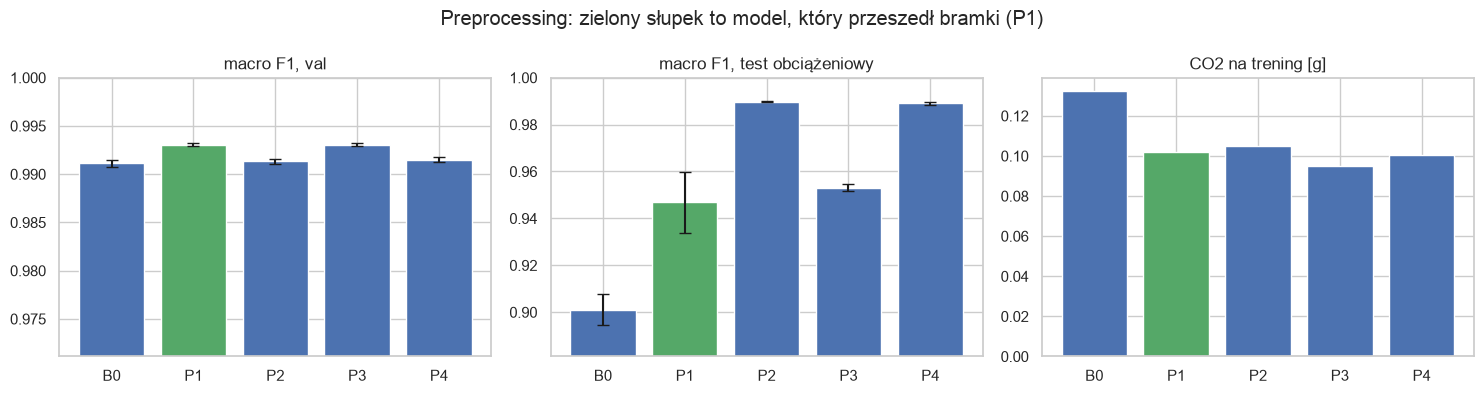

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
order = list(results)
for ax, col, title in zip(axes, ["val_macro_f1", "val_stress_macro_f1", "co2_g"],
                          ["macro F1, val", "macro F1, test obciążeniowy", "CO2 na trening [g]"]):
    err = table[f"{col}_std"] if f"{col}_std" in table else None
    ax.bar(order, table.loc[order, col], yerr=None if err is None else table.loc[order, f"{col}_std"],
           color=[sns.color_palette()[2] if i == current_id else sns.color_palette()[0] for i in order], capsize=4)
    ax.set_title(title)
    if col != "co2_g":
        lo = table.loc[order, col].min()
        ax.set_ylim(max(0, lo - 0.02), 1.0)
plt.suptitle(f"Preprocessing: zielony słupek to model, który przeszedł bramki ({current_id})")
plt.tight_layout(); plt.savefig(FIG / "preprocessing_comparison.png", dpi=150); plt.show()

## Która część testu obciążeniowego szkodzi?

Rozkładamy test obciążeniowy na pojedyncze przekształcenia i sprawdzamy na nich modele z ziarna 0.
Bez ponownego treningu, więc ta analiza prawie nic nie kosztuje.

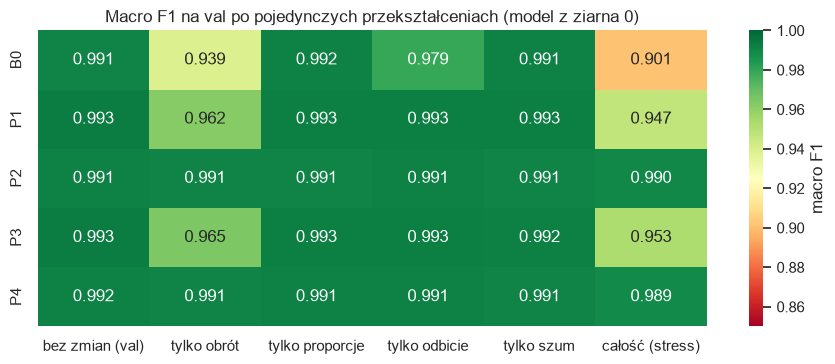

In [5]:
import pickle
import numpy as np
from pipeline import STRESS_PARTS, transform

ablation = {}
for exp_id, prep_name in [("B0", "raw")] + [(e, p) for e, p, _ in variants]:
    model = pickle.load(open(f"../models/{exp_id}.pkl", "rb"))
    prep = PREPROCESS[prep_name]
    row = {"bez zmian (val)": table.loc[exp_id, "val_macro_f1"]}
    for part, kw in STRESS_PARTS.items():
        row[part] = f1_macro(model, prep(transform(lm_va, np.random.default_rng(123), **kw)), y_va)
    row["całość (stress)"] = table.loc[exp_id, "val_stress_macro_f1"]
    ablation[exp_id] = row
ablation = pd.DataFrame(ablation).T
plt.figure(figsize=(9, 3.8))
sns.heatmap(ablation, annot=True, fmt=".3f", cmap="RdYlGn", vmin=0.85, vmax=1.0, cbar_kws={"label": "macro F1"})
plt.title("Macro F1 na val po pojedynczych przekształceniach (model z ziarna 0)")
plt.tight_layout(); plt.savefig(FIG / "preprocessing_stress_ablation.png", dpi=150); plt.show()

In [6]:
chosen = {"B0": "raw", **{e: p for e, p, _ in variants}}[current_id]
gates = json.loads(GATES.read_text())
gates["preprocessing"] = {"experiment_id": current_id, "preprocess": chosen}
GATES.write_text(json.dumps(gates, indent=2, ensure_ascii=False))
print("Do kolejnego kroku idzie:", current_id, chosen)

Do kolejnego kroku idzie: P1 wrist_scale


## Wnioski

- **P1 przechodzi bramkę.** Przesunięcie nadgarstka do (0, 0) i skalowanie podnosi test obciążeniowy z 0.901
  do 0.947 (+0.046 przy progu szumu 0.026), a val z 0.9911 do 0.9931. Trening jest nawet krótszy (37 s zamiast
  49 s, 0.10 g zamiast 0.13 g CO2). Rozmiar i czas predykcji bez zmian. Wygrywa jakość i GreenAI.
- **Analiza przekształceń pokazuje, skąd zysk.** B0 traci na odbiciu lustrzanym (0.979), P1 już nie (0.993).
  Prawdopodobnie B0 uczył się z położenia dłoni w kadrze, a odbita dłoń w tym samym miejscu go myli.
  Obu modelom szkodzi głównie obrót (0.939 i 0.962), bo w HaGRID prawie wszystkie dłonie są pionowe.
- **P2 (obrót do pionu) rozwiązuje problem obrotu, ale bramka go odrzuca.** Test obciążeniowy rośnie do 0.990,
  a na samym obrocie model ma 0.991 zamiast 0.962. Za to val spada z 0.9931 do 0.9913. Spadek jest mały, ale
  wyraźnie większy niż szum (0.0006), a nasza reguła bramki, ustalona przed eksperymentami, nie pozwala na spadek val.
  Reguły nie zmieniamy po fakcie. Sprawdzimy w kroku augmentacji, czy tę samą odporność da się uzyskać z danych.
- **P3 (kąty w stawach) nic nie wnosi.** +0.006 na teście obciążeniowym to mniej niż szum, a model rośnie
  o 13% (198 KB zamiast 175 KB), bo ma 57 cech zamiast 42. Odrzucony. P4 (obrót + kąty) zachowuje się jak P2,
  tylko jest większy.

**Błędna ścieżka, którą warto opisać.** W pierwszym uruchomieniu P2 wypadł gorzej niż P1 (0.933). Analiza
przekształceń to wyjaśniła. Model po obrocie do pionu nie powinien w ogóle reagować na sam obrót, a reagował.
Przyczyną był błąd znaku w funkcji obrotu. Dłoń obracała się o podwójny kąt zamiast wracać do pionu. Po poprawce
(`src/pipeline.py`, funkcja `_upright`) P2 zachowuje się zgodnie z teorią. Wniosek: test, który rozbija wynik na
części, łapie błędy implementacji, których sama średnia nie pokaże.

**Do kolejnego kroku idzie P1** (`wrist_scale`).